# SE4042 · Topic 5 Lab — The Lattice Boltzmann Method

# Part 0 — One sandbox, two languages

In [ ]:
# --- Cell 0.1: install Julia (juliaup) into this Colab VM; ~1 minute
!curl -fsSL https://install.julialang.org | sh -s -- --yes
import os
os.environ["PATH"] = os.path.expanduser("~/.juliaup/bin") + ":" + os.environ["PATH"]
!julia --version
!python3 --version
!python3 -c "import numpy; print('numpy', numpy.__version__)"


info: downloading installer
Welcome to Julia!

This will download and install the official Julia Language distribution
and its version manager Juliaup.

Juliaup will be installed into the Juliaup home directory, located at:

  /root/.juliaup

The julia, juliaup and other commands will be added to
Juliaup's bin directory, located at:

  /root/.juliaup/bin

This path will then be added to your PATH environment variable by
modifying the profile files located at:

  /root/.bashrc
  /root/.profile

Julia will look for a new version of Juliaup itself every 1440 minutes when you start julia.

You can uninstall at any time with juliaup self uninstall and these
changes will be reverted.

Now installing Juliaup
    Checking for new Julia versions
  Installing Julia 1.13.2+0.x64.linux.gnu
         Add Installed Julia channel 'release'
   Configure Default Julia version set to 'release'.
Julia was successfully installed on your system.

Depending on which shell you are using, run one of the follo

# Part 1 — One node, one collision

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

# ---- D2Q9 lattice (Listing 5.2) ----------------------------------------------
ex  = np.array([0, 1, 0, -1, 0, 1, -1, -1, 1])           # x-component of e_i
ey  = np.array([0, 0, 1, 0, -1, 1, 1, -1, -1])           # y-component of e_i
w   = np.array([4, 1, 1, 1, 1, 1/4, 1/4, 1/4, 1/4]) / 9   # weights w_i
opp = np.array([0, 3, 4, 1, 2, 7, 8, 5, 6])              # opp[i]: reversed i

def moments(f):
    """Density and velocity at every node: the zeroth and first moments."""
    rho = f.sum(axis=0)
    ux = (ex[:, None, None] * f).sum(axis=0) / rho
    uy = (ey[:, None, None] * f).sum(axis=0) / rho
    return rho, ux, uy

def equilibrium(rho, ux, uy):
    """Discrete Maxwell-Boltzmann equilibrium, 2nd order in the velocity."""
    cu = 3.0 * (ex[:, None, None] * ux + ey[:, None, None] * uy) # e_i.u/c_s^2
    u2 = 1.5 * (ux**2 + uy**2)                                    # u.u/(2c_s^2)
    return w[:, None, None] * rho * (1.0 + cu + 0.5 * cu**2 - u2)

def collide(f, tau):
    """BGK collision: relax each population a fraction 1/tau to equilibrium."""
    rho, ux, uy = moments(f)
    return f - (f - equilibrium(rho, ux, uy)) / tau

def stream(f):
    """Move each population one node along its own velocity.  np.roll wraps
    both edges (periodic in x and y); a non-periodic edge must overwrite the
    wrapped populations afterwards -- see Listing 5.4."""
    g = np.empty_like(f)
    for i in range(9):
        g[i] = np.roll(f[i], shift=(ex[i], ey[i]), axis=(0, 1))
    return g

def step(f, tau):
    """One lattice Boltzmann time step on a fully periodic domain."""
    return stream(collide(f, tau))

## Task 1.1 — Moments by hand, then by code

By hand: ρ = 0.40 + 0.12 + 0.10 + 0.08 + 0.10 + 0.030 + 0.025 + 0.025 + 0.030 = 0.910;
ρu<sub>x</sub> = 0.12 − 0.08 + 0.030 − 0.025 − 0.025 + 0.030 = 0.050, so u<sub>x</sub> = 0.050 / 0.910 = 0.0549.

u<sub>y</sub> is exactly zero because the populations are up–down symmetric: f₂ = f₄ (0.10), f₅ = f₈ (0.030)
and f₆ = f₇ (0.025), so every upward contribution is cancelled by an equal downward one.

In [ ]:
# Listing 5.1
f = np.array([0.40, 0.12, 0.10, 0.08, 0.10,
              0.030, 0.025, 0.025, 0.030])     # nine populations at one node

rho = f.sum()                                  # density = zeroth moment
ux = (ex * f).sum() / rho                      # x-velocity = 1st moment / rho
uy = (ey * f).sum() / rho
print(f"rho = {rho:.3f}, ux = {ux:+.4f}, uy = {uy:+.4f}")

rho = 0.910, ux = +0.0549, uy = +0.0000


## Task 1.2 — The equilibrium conserves what it must

In [ ]:
f_node = f.reshape(9, 1, 1)
rho_n, ux_n, uy_n = moments(f_node)
feq = equilibrium(rho_n, ux_n, uy_n)

print(f"sum f_eq          = {feq.sum():.3f}")
print(f"sum f_eq e_x / rho = {(ex[:, None, None] * feq).sum() / rho_n.item():.4f}")
print(f"f1_eq = {feq[1].item():.4f}  vs  f1 = {f[1]:.3f}")
print(f"f3_eq = {feq[3].item():.4f}  vs  f3 = {f[3]:.3f}")

sum f_eq          = 0.910
sum f_eq e_x / rho = 0.0549
f1_eq = 0.1187  vs  f1 = 0.120
f3_eq = 0.0854  vs  f3 = 0.080


## Task 1.3 — Relax one node and watch τ do its work

**Prediction.** The ratio is 1 − 1/τ. τ = 1 gives zero (straight to equilibrium); τ = 0.8 and 0.6
give a negative ratio (over-relaxation: the deviation flips sign but shrinks); τ = 0.45 gives
|ratio| > 1, so the deviation grows.

In [ ]:
for tau in (2.0, 1.0, 0.8, 0.6, 0.45):
    f_new = collide(f_node, tau)
    ratio = (f_new - feq)[1].item() / (f_node - feq)[1].item()
    print(f"tau = {tau:<4}: ratio = {ratio:+.4f}   (1 - 1/tau = {1 - 1/tau:+.4f})")

g = f_node.copy()
for _ in range(10):
    g = collide(g, 0.45)
print(f"\ntau = 0.45, ten collisions: max|f - feq| = {np.abs(g - feq).max():.3f} "
      f"(initially {np.abs(f_node - feq).max():.4f}; population 1: {abs((f_node - feq)[1].item()):.4f})")
print(f"populations after ten collisions: {np.round(g.ravel(), 4)}")

tau = 2.0 : ratio = +0.5000   (1 - 1/tau = +0.5000)
tau = 1.0 : ratio = +0.0000   (1 - 1/tau = +0.0000)
tau = 0.8 : ratio = -0.2500   (1 - 1/tau = -0.2500)
tau = 0.6 : ratio = -0.6667   (1 - 1/tau = -0.6667)
tau = 0.45: ratio = -1.2222   (1 - 1/tau = -1.2222)

tau = 0.45, ten collisions: max|f - feq| = 0.040 (initially 0.0054; population 1: 0.0013)
populations after ten collisions: [0.3832 0.1284 0.0958 0.0455 0.0958 0.0321 0.0486 0.0486 0.0321]


## Task 1.4 — The rest test

In [ ]:
# sanity check: a uniform fluid at rest must stay exactly at rest (Listing 5.2)
f = equilibrium(np.ones((40, 40)), np.zeros((40, 40)), np.zeros((40, 40)))
for _ in range(50):
    f = step(f, tau=0.8)
rho, ux, uy = moments(f)
print(f"rest fluid: max|u| = {np.hypot(ux, uy).max():.1f}"
      f"   density spread = {rho.max() - rho.min():.1f}")

rest fluid: max|u| = 0.0   density spread = 0.0


# Part 2 — Build the core, validate against Poiseuille

In [ ]:
# Listing 5.4 (bounce-back) and Listing 5.5 (Guo forcing)
def bounce_back(f_pre, f_post, solid):
    """No-slip wall (full-way bounce-back).  At every solid node the collision
    is replaced by reflection: each population that streamed in is sent back
    the way it came, so it leaves along the reversed direction next step."""
    f_out = f_post.copy()
    f_out[:, solid] = f_pre[opp][:, solid]      # f_out[i] <- f_pre[opp[i]]
    return f_out

def moments_forced(f, gx):
    """Moments with the half-force velocity shift required by Guo forcing."""
    rho = f.sum(axis=0)
    ux = ((ex[:, None, None] * f).sum(axis=0) + 0.5 * gx * rho) / rho
    uy = (ey[:, None, None] * f).sum(axis=0) / rho
    return rho, ux, uy

def collide_forced(f, tau, gx):
    """BGK collision plus a uniform body force gx per unit mass (Guo 2002)."""
    rho, ux, uy = moments_forced(f, gx)
    feq = equilibrium(rho, ux, uy)
    eu = ex[:, None, None] * ux + ey[:, None, None] * uy
    S = w[:, None, None] * rho * (3.0 * (ex[:, None, None] - ux)
                                  + 9.0 * eu * ex[:, None, None]) * gx
    return f - (f - feq) / tau + (1.0 - 0.5 / tau) * S

In [ ]:
def poiseuille_run(N=40, tau=1.0, g=1e-6, steps=30000):
    """Steady channel flow driven by body force g; returns the fluid-node velocity profile."""
    NX, NY = 4, N + 2                                     # two solid rows, periodic in x
    solid = np.zeros((NX, NY), bool); solid[:, 0] = solid[:, -1] = True
    z = np.zeros((NX, NY)); f = equilibrium(np.ones((NX, NY)), z, z)
    for _ in range(steps):
        f_post = bounce_back(f, collide_forced(f, tau, g), solid)
        f = stream(f_post)
    rho, ux, uy = moments_forced(f, g)
    return ux[0, 1:-1]

def u_exact(N, tau, g, walls="halfway"):
    y = np.arange(N); nu = (tau - 0.5) / 3
    if walls == "halfway":                                # E16, correct
        return g/(2*nu) * (y + 0.5) * (N - 0.5 - y)
    return g/(2*nu) * (y + 1.0) * (N - y)                 # walls AT the solid nodes

def poiseuille_error(N=40, tau=1.0, g=1e-6, steps=30000, walls="halfway"):
    # steady channel flow driven by body force g; returns max |u - u_exact| / u_max
    u = poiseuille_run(N, tau, g, steps)
    ue = u_exact(N, tau, g, walls)
    return np.abs(u - ue).max() / ue.max()

## Task 2.1 — The chapter's number

max |u - u_exact| / u_max = 2.1e-04
error per node: min 2.085e-04, max 2.085e-04 (uniform slip)


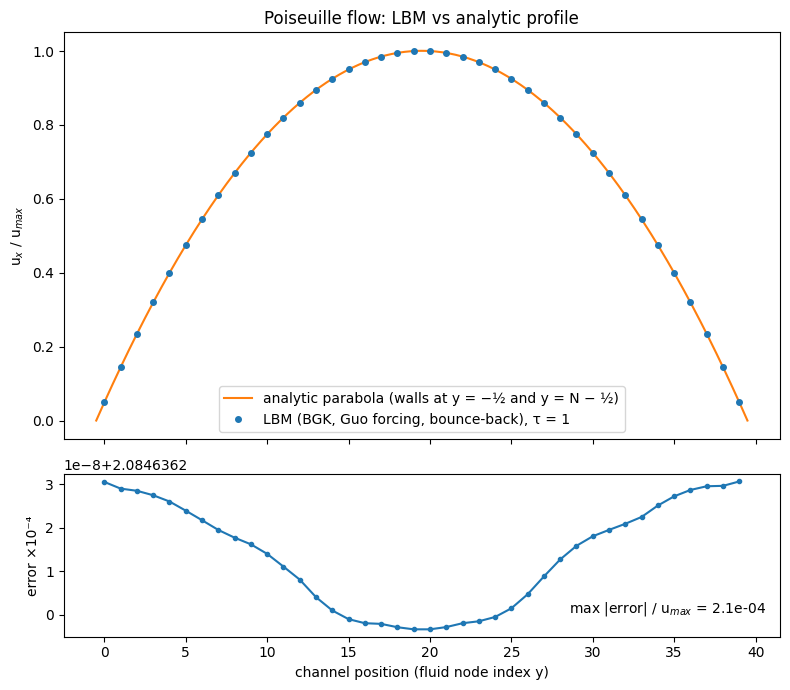

In [ ]:
N, TAU_P, G = 40, 1.0, 1e-6
u_lbm = poiseuille_run(N, TAU_P, G)
u_ex = u_exact(N, TAU_P, G)
err = (u_lbm - u_ex) / u_ex.max()
print(f"max |u - u_exact| / u_max = {np.abs(err).max():.1e}")
print(f"error per node: min {err.min():.3e}, max {err.max():.3e} (uniform slip)")

y = np.arange(N)
y_fine = np.linspace(-0.5, N - 0.5, 400)
nu = (TAU_P - 0.5) / 3
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1.2]})
a1.plot(y_fine, G/(2*nu) * (y_fine + 0.5) * (N - 0.5 - y_fine) / u_ex.max(),
        color="tab:orange", label="analytic parabola (walls at y = −½ and y = N − ½)")
a1.plot(y, u_lbm / u_ex.max(), "o", color="tab:blue", ms=4,
        label="LBM (BGK, Guo forcing, bounce-back), τ = 1")
a1.set(ylabel="u$_x$ / u$_{max}$", title="Poiseuille flow: LBM vs analytic profile")
a1.legend(loc="lower center")
a2.plot(y, err * 1e4, "o-", ms=3)
a2.set(xlabel="channel position (fluid node index y)", ylabel="error ×10⁻⁴")
a2.text(0.98, 0.15, f"max |error| / u$_{{max}}$ = {np.abs(err).max():.1e}",
        transform=a2.transAxes, ha="right")
fig.tight_layout()
fig.savefig("poiseuille.png", dpi=150)
plt.show()

## Task 2.2 — The wall experiment

**Prediction.** The error goes **up**, a lot: the LBM velocities are unchanged, but the analytic
formula now puts the walls one half-node too far out, so it describes a wider channel.

In [ ]:
e_half = poiseuille_error()
e_solid = poiseuille_error(walls="solid")
print(f"walls halfway : {e_half:.1e}")
print(f"walls at solid: {e_solid:.1%}   ({e_solid / e_half:.0f}x worse)")

walls halfway : 2.1e-04
walls at solid: 4.8%   (230x worse)


## Task 2.3 — The magic τ

In [ ]:
tau_magic = 0.5 + np.sqrt(3) / 4
print(f"tau = 0.8   : {poiseuille_error(tau=0.8):.1e}")
print(f"tau = {tau_magic:.3f} : {poiseuille_error(tau=tau_magic, steps=60000):.0e}")

tau = 0.8   : 3.3e-04
tau = 0.933 : 5e-12


The bounce-back slip depends on τ and vanishes at τ = ½ + √3/4, so "the error of bounce-back"
means nothing unless the τ it was measured at is stated.

## Task 2.4 — Convergence

N = 10: error = 3.37e-03
N = 20: error = 8.35e-04
N = 40: error = 2.08e-04
N = 80: error = 5.21e-05
error ratio per doubling: [4.03 4.01 4.  ]
fitted order = 2.00


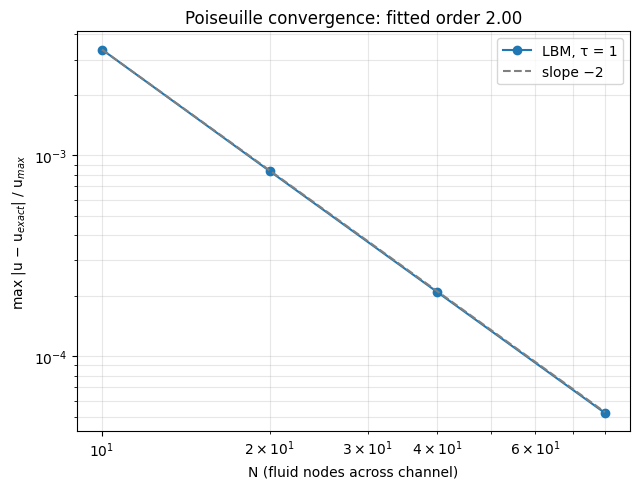

In [ ]:
Ns = np.array([10, 20, 40, 80])
errs = np.array([poiseuille_error(N=n, tau=1.0, g=1e-6 * (40/n)**2, steps=30000 * n // 40)
                 for n in Ns])
order = -np.polyfit(np.log(Ns), np.log(errs), 1)[0]
for n, e in zip(Ns, errs):
    print(f"N = {n:>2}: error = {e:.2e}")
print("error ratio per doubling:", np.round(errs[:-1] / errs[1:], 2))
print(f"fitted order = {order:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.loglog(Ns, errs, "o-", label="LBM, τ = 1")
ax.loglog(Ns, errs[0] * (Ns / Ns[0])**-2.0, "--", color="grey", label="slope −2")
ax.set(xlabel="N (fluid nodes across channel)", ylabel="max |u − u$_{exact}$| / u$_{max}$",
       title=f"Poiseuille convergence: fitted order {order:.2f}")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
fig.savefig("convergence.png", dpi=150)
plt.show()

# Part 3 — A vortex street from scratch

In [17]:
# Listing 5.4 (open boundaries)
def inlet_zou_he(f, u_in):
    """Velocity inlet on the left column, x = 0 (Zou & He 1997).
    After streaming, populations 1, 5, 8 at x = 0 have no upstream node and
    are unknown.  Reconstruct them so that the node carries velocity (u_in, 0)
    and a density consistent with the six known populations."""
    f0, f2, f3, f4, f6, f7 = (f[i, 0, :] for i in (0, 2, 3, 4, 6, 7))
    rho = (f0 + f2 + f4 + 2.0 * (f3 + f6 + f7)) / (1.0 - u_in)
    g = f.copy()
    g[1, 0, :] = f3 + (2.0/3.0) * rho * u_in
    g[5, 0, :] = f7 - 0.5 * (f2 - f4) + (1.0/6.0) * rho * u_in
    g[8, 0, :] = f6 + 0.5 * (f2 - f4) + (1.0/6.0) * rho * u_in
    return g

def outlet_zero_gradient(f):
    """Outflow on the right column, x = NX-1: the unknown populations 3, 6, 7
    are copied from the neighbour upstream, so the flow leaves undisturbed."""
    g = f.copy()
    g[[3, 6, 7], -1, :] = f[[3, 6, 7], -2, :]
    return g

In [ ]:
def karman(NX, NY, tau, u0, steps, cx, cy, r, probe=None, swap_order=False):
    """Flow past a cylinder: Zou-He inlet (left), zero-gradient outlet,
    periodic top and bottom, bounce-back on the cylinder.  (Listing 5.6,
    plus the probe bookkeeping: uy at `probe` recorded every step.)"""
    X, Y = np.meshgrid(np.arange(NX), np.arange(NY), indexing="ij")
    solid = (X - cx)**2 + (Y - cy)**2 < r*r                     # obstacle mask
    u_in = u0 * (1 + 1e-3 * np.sin(2*np.pi*np.arange(NY)/NY))  # tiny seed
    f = equilibrium(np.ones((NX, NY)), np.full((NX, NY), u0),
                    np.zeros((NX, NY)))                         # start at feq
    signal, nan_step = [], None
    for t in range(steps):
        f_post = collide(f, tau)                   # 1. collide in the fluid
        f_post = bounce_back(f, f_post, solid)     # 2. reflect at the solid
        if swap_order:
            f_post = inlet_zou_he(f_post, u_in)    #    (wrong: inlet before stream)
            f = stream(f_post)
        else:
            f = stream(f_post)                     # 3. move the populations
            f = inlet_zou_he(f, u_in)              # 4. rebuild inlet unknowns
        f = outlet_zero_gradient(f)                # 5. rebuild outlet unknowns
        if probe is not None:
            fp = f[:, probe[0], probe[1]]
            signal.append((ey * fp).sum() / fp.sum())
        if not np.isfinite(f.sum()):
            nan_step = t + 1
            break
    rho, ux, uy = moments(f)
    return rho, ux, uy, solid, np.array(signal), nan_step


def vorticity(ux, uy):
    return np.gradient(uy, axis=0) - np.gradient(ux, axis=1)


def plot_vorticity(ux, uy, solid, title, fname, probe=None):
    vort = np.ma.masked_where(solid, vorticity(ux, uy)).T
    lim = np.percentile(np.abs(vort.compressed()), 99)          # clip the wall peaks so the wake shows
    fig, ax = plt.subplots(figsize=(11, 4.5))
    im = ax.imshow(vort, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.imshow(np.ma.masked_where(~solid.T, solid.T), origin="lower", cmap="Greys", vmin=0, vmax=2)
    if probe is not None:
        ax.plot(*probe, "k+", ms=12, mew=2, label="probe")
        ax.legend(loc="upper right")
    ax.set(xlabel="x (lattice nodes)", ylabel="y (lattice nodes)", title=title)
    fig.colorbar(im, ax=ax, label="vorticity ω (lattice units)", shrink=0.8, extend="both")
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    plt.show()

## Task 3.1 — Run it and look (Re = 100, about 5 minutes)

run time: 123 s
first step with |uy| at probe > 5% of U: 13998
peak speed in the field = 1.55 U  ->  local Mach = 0.13


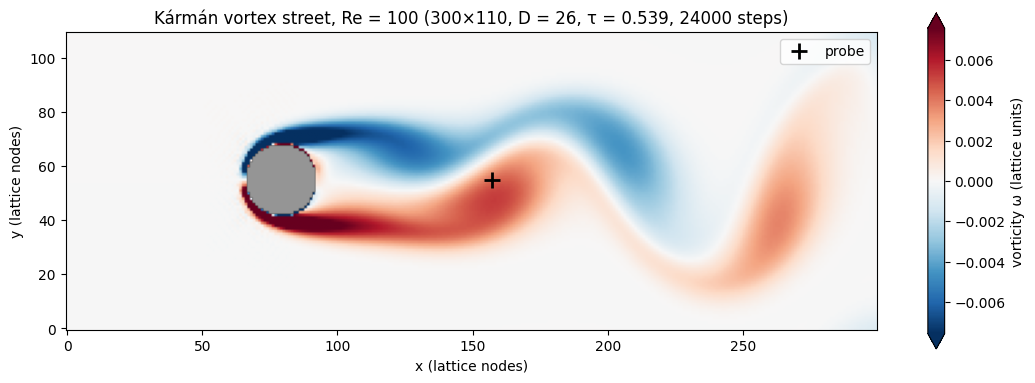

In [18]:
NX, NY = 300, 110
R, CX, CY = 13, 79, 55
D, U0, TAU_K = 2 * R, 0.05, 0.539
PROBE = (CX + 3 * D, CY)
STEPS = 24000

t0 = time.perf_counter()
rho, ux, uy, solid, sig, _ = karman(NX, NY, TAU_K, U0, STEPS, CX, CY, R, probe=PROBE)
print(f"run time: {time.perf_counter() - t0:.0f} s")

onset = int(np.argmax(np.abs(sig) > 0.05 * U0))          # steps counted from 0
speed = np.where(solid, 0, np.hypot(ux, uy))
print(f"first step with |uy| at probe > 5% of U: {onset}")
print(f"peak speed in the field = {speed.max() / U0:.2f} U  ->  "
      f"local Mach = {speed.max() * np.sqrt(3):.2f}")

plot_vorticity(ux, uy, solid, f"Kármán vortex street, Re = 100 ({NX}×{NY}, D = {D}, τ = {TAU_K}, "
               f"{STEPS} steps)", "vortex_street.png", probe=PROBE)

## Task 3.2 — Measure the Strouhal number

3 upward zero-crossings in the last 8000 steps
period T = 2594 steps  ->  St = D / (T U) = 0.200


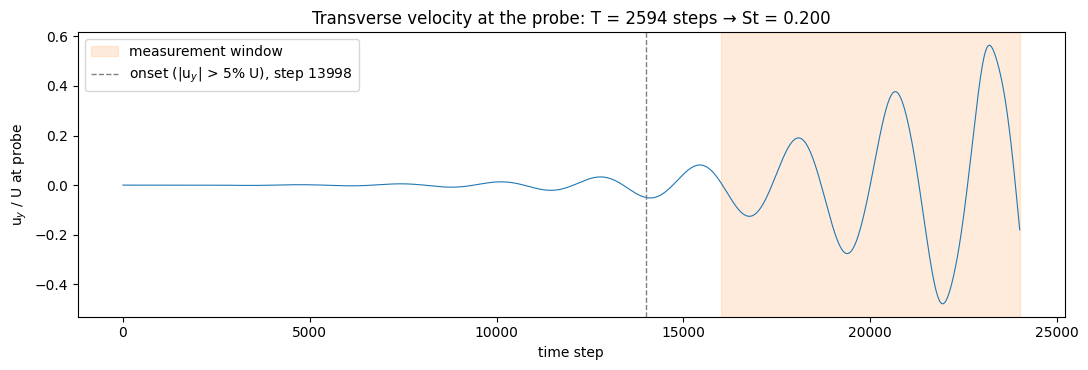

In [19]:
WINDOW = 8000
s = sig[-WINDOW:] - sig[-WINDOW:].mean()
up = np.flatnonzero((s[:-1] < 0) & (s[1:] >= 0))
T = np.diff(up).mean()
St = D / (T * U0)
print(f"{len(up)} upward zero-crossings in the last {WINDOW} steps")
print(f"period T = {T:.0f} steps  ->  St = D / (T U) = {St:.3f}")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.arange(len(sig)), sig / U0, lw=0.8)
ax.axvspan(len(sig) - WINDOW, len(sig), color="tab:orange", alpha=0.15, label="measurement window")
ax.axvline(onset, color="grey", ls="--", lw=1, label=f"onset (|u$_y$| > 5% U), step {onset}")
ax.set(xlabel="time step", ylabel="u$_y$ / U at probe",
       title=f"Transverse velocity at the probe: T = {T:.0f} steps → St = {St:.3f}")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("probe_signal.png", dpi=150)
plt.show()

St ≈ 0.200 sits above the experimental 0.164 because the periodic top and bottom make the 110-node
channel act like a wind tunnel with blockage D/N<sub>Y</sub> = 24 %, which speeds the flow past the
cylinder and raises the shedding frequency. The chapter's runs show the trend (16 % → 0.190,
8 % → 0.178, i.e. St ≈ 0.166 + 0.15 × blockage), so a 300 × 220 run (blockage 12 %) should land
near **St ≈ 0.18**.

## Task 3.3 — Below the onset (Re = 40)

**Prediction.** Re = 40 is below the shedding threshold (Re ≈ 47), so the probe signal should stay
flat: the tiny inlet seed decays instead of growing, and the wake stays a steady pair of eddies.

tau = 0.598
max |uy| / U at probe (whole run)       = 0.000
max |uy| / U at probe (last 5000 steps) = 0.000


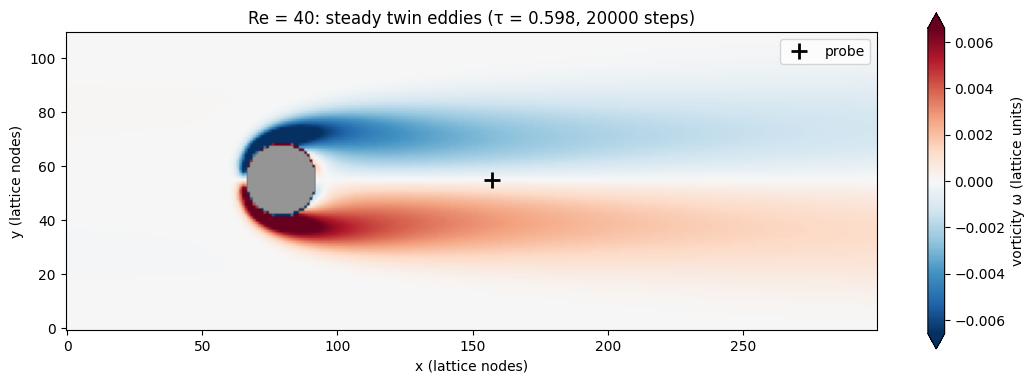

In [20]:
TAU_40 = 0.5 + 3 * U0 * D / 40
rho40, ux40, uy40, solid40, sig40, _ = karman(NX, NY, TAU_40, U0, 20000, CX, CY, R, probe=PROBE)
print(f"tau = {TAU_40:.3f}")
print(f"max |uy| / U at probe (whole run)       = {np.abs(sig40).max() / U0:.3f}")
print(f"max |uy| / U at probe (last 5000 steps) = {np.abs(sig40[-5000:]).max() / U0:.3f}")
plot_vorticity(ux40, uy40, solid40, f"Re = 40: steady twin eddies (τ = {TAU_40:.3f}, 20000 steps)",
               "re40_steady_wake.png", probe=PROBE)

## Task 3.4 — Push τ to the floor (τ = 0.52, Re = 173)

**Prediction.** τ − ½ = 0.02 leaves too little stability margin for BGK, so the run should blow up
to NaN well before shedding starts.

In [21]:
TAU_FLOOR = 0.52
_, _, _, _, _, nan_step = karman(NX, NY, TAU_FLOOR, U0, 5000, CX, CY, R)
print(f"Re = {U0 * D / ((TAU_FLOOR - 0.5) / 3):.0f}: NaN first appears at step {nan_step}")

nu_safe = (0.539 - 0.5) / 3
D_min = 173 * nu_safe / U0
print(f"smallest D for Re = 173 at tau = 0.539, U = 0.05: D = Re*nu/U = {D_min:.1f} -> D = {np.ceil(D_min):.0f}")
print(f"cost grows as D^3: ({np.ceil(D_min):.0f}/26)^3 = {(np.ceil(D_min) / 26)**3:.1f}x longer")

Re = 195: NaN first appears at step 893
smallest D for Re = 173 at tau = 0.539, U = 0.05: D = Re*nu/U = 45.0 -> D = 45
cost grows as D^3: (45/26)^3 = 5.2x longer


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:53: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


From E11, ν = c<sub>s</sub>²(τ − ½) = 0.013 at τ = 0.539, so Re = UD/ν = 173 needs D = 173 × 0.013 / 0.05 ≈ 45
nodes. Doubling D quadruples the nodes and doubles the steps, so the cost scales as D³:
(45/26)³ ≈ 5× longer.

Note: with D = 26 and τ = 0.52, Re = UD/ν = 0.05 × 26 / (0.02/3) = 195 rather than the sheet's 173; for Re = 195 the same argument gives D ≈ 51 and (51/26)³ ≈ 7.5× longer.

## Why the order of the five lines matters

In [22]:
for swap in (False, True):
    rho_o, ux_o, *_ = karman(NX, NY, TAU_K, U0, 500, CX, CY, R, swap_order=swap)
    label = "inlet BEFORE stream (wrong)" if swap else "inlet AFTER stream (correct)"
    print(f"{label:<30}: rho.min() = {rho_o.min():.4f}, rho.max() = {rho_o.max():.4f} | "
          f"inlet ux = {ux_o[0].min():.4f} .. {ux_o[0].max():.4f} (target {U0})")

inlet AFTER stream (correct)  : rho.min() = 0.9717, rho.max() = 1.0326 | inlet ux = 0.0500 .. 0.0500 (target 0.05)
inlet BEFORE stream (wrong)   : rho.min() = 0.9711, rho.max() = 1.0312 | inlet ux = 0.0469 .. 0.0524 (target 0.05)


The density range barely changes in 500 steps, but the inlet does: in the correct order the inlet
column carries exactly u = 0.05, while with the inlet applied before streaming `np.roll` overwrites the
reconstructed populations with the outlet's wrapped ones, so the inlet velocity drifts away from the
prescribed value. The correct order is kept in `karman` above.

# Part 4 — The shoot-out: pure Python vs NumPy vs Julia

## Task 4.1 — Pure Python (the baseline)

In [23]:
# --- Cell 4.1: pure-Python loops, one step, 200 x 200
import time
NX = NY = 200; TAU = 0.8
EX = [0, 1, 0, -1, 0, 1, -1, -1, 1]
EY = [0, 0, 1, 0, -1, 1, 1, -1, -1]
W  = [4/9, 1/9, 1/9, 1/9, 1/9, 1/36, 1/36, 1/36, 1/36]

def init_lists():
    ux, uy = 0.03, 0.0; u2 = 1.5*(ux*ux + uy*uy)
    f = [[[W[i]*(1 + 3*EX[i]*ux + 0.5*(3*EX[i]*ux)**2 - u2)
           for y in range(NY)] for x in range(NX)] for i in range(9)]
    f[1][100][100] += 0.05
    return f

def step_lists(f):
    g = [[[0.0]*NY for _ in range(NX)] for _ in range(9)]
    for x in range(NX):
        for y in range(NY):
            rho = mx = my = 0.0
            for i in range(9):
                v = f[i][x][y]; rho += v; mx += v*EX[i]; my += v*EY[i]
            ux, uy = mx/rho, my/rho; u2 = 1.5*(ux*ux + uy*uy)
            for i in range(9):
                cu = 3.0*(EX[i]*ux + EY[i]*uy)
                feq = W[i]*rho*(1 + cu + 0.5*cu*cu - u2)
                v = f[i][x][y]
                g[i][(x + EX[i]) % NX][(y + EY[i]) % NY] = v - (v - feq)/TAU
    return g

f = init_lists()
t0 = time.perf_counter(); g = step_lists(f); t_py = time.perf_counter() - t0
cells = [(i, x, y) for i in range(9) for x in range(NX) for y in range(NY)]
mass = sum(g[i][x][y] for i, x, y in cells)
momx = sum(g[i][x][y]*EX[i] for i, x, y in cells)
mlups = NX*NY/t_py/1e6
print(f"pure Python loops : {t_py*1000:8.1f} ms per step  ({mlups:6.2f} MLUPS)")
print(f"mass             = {mass:.15e}")
print(f"x-momentum       = {momx:.15e}")
print(f"f1 shifted node  = {g[1][101][100]:.15e}")
check_py = (mass, momx, g[1][101][100])

pure Python loops :    207.3 ms per step  (  0.19 MLUPS)
mass             = 4.000005000000000e+04
x-momentum       = 1.200050000000002e+03
f1 shifted node  = 1.388535714285714e-01


## Task 4.2 — NumPy

In [24]:
# --- Cell 4.2: NumPy, same problem, 20 timed steps after a warm-up
z = np.zeros((NX, NY))
f = equilibrium(np.ones((NX, NY)), z + 0.03, z); f[1, 100, 100] += 0.05
step = lambda f: stream(collide(f, TAU))
for _ in range(3): step(f)                                   # warm-up
t0 = time.perf_counter()
for _ in range(20): g = step(f)
t_np = (time.perf_counter() - t0) / 20
mlups = NX*NY/t_np/1e6
print(f"NumPy vectorised  : {t_np*1000:8.2f} ms per step  ({mlups:6.1f} MLUPS)")
print(f"mass             = {g.sum():.15e}")
print(f"x-momentum       = {(g * ex[:, None, None]).sum():.15e}")
print(f"f1 shifted node  = {g[1, 101, 100]:.15e}")
check_np = (g.sum(), (g * ex[:, None, None]).sum(), g[1, 101, 100])

NumPy vectorised  :     4.78 ms per step  (   8.4 MLUPS)
mass             = 4.000005000000000e+04
x-momentum       = 1.200050000000001e+03
f1 shifted node  = 1.388535714285714e-01


## Task 4.3 — Julia (fused loops, Listing 5.7 with streaming added)

In [25]:
%%writefile lbm_bench.jl
# lbm_bench.jl -- D2Q9 BGK, one collide+stream step on a 200 x 200 lattice.
# Fused loops, two arrays, periodic wrap. Same test case as the Python cells.
using Printf

const ex = (0, 1, 0, -1, 0, 1, -1, -1, 1)
const ey = (0, 0, 1, 0, -1, 1, 1, -1, -1)
const w  = (4/9, 1/9, 1/9, 1/9, 1/9, 1/36, 1/36, 1/36, 1/36)

function init(NX, NY)            # f[k, x, y]: nine populations per node, contiguous
    f = zeros(Float64, 9, NX, NY)
    ux, uy = 0.03, 0.0
    u2 = 1.5 * (ux^2 + uy^2)
    for y in 1:NY, x in 1:NX, k in 1:9
        cu = 3 * (ex[k]*ux + ey[k]*uy)
        f[k, x, y] = w[k] * (1 + cu + 0.5*cu^2 - u2)
    end
    f[2, 101, 101] += 0.05           # Python: f[1, 100, 100] += 0.05
    return f
end

function step!(g, f, tau)      # moments -> feq -> relax -> stream, one pass
    NX, NY = size(f, 2), size(f, 3)
    inv = 1 / tau
    @inbounds for y in 1:NY, x in 1:NX
        rho = 0.0; mx = 0.0; my = 0.0
        for k in 1:9
            fk = f[k, x, y]; rho += fk; mx += ex[k]*fk; my += ey[k]*fk
        end
        ux = mx / rho; uy = my / rho; u2 = 1.5 * (ux*ux + uy*uy)
        for k in 1:9
            cu  = 3 * (ex[k]*ux + ey[k]*uy)
            feq = w[k] * rho * (1 + cu + 0.5*cu*cu - u2)
            xt = mod1(x + ex[k], NX); yt = mod1(y + ey[k], NY)  # periodic
            g[k, xt, yt] = f[k, x, y] - (f[k, x, y] - feq) * inv  # collide+stream
        end
    end
    return g
end

NX = NY = 200
f = init(NX, NY); g = similar(f)
step!(g, f, 0.8)                 # warm-up: the first call compiles step!
n = 20
t = @elapsed for _ in 1:n; step!(g, f, 0.8); end
ms = t / n * 1000
mlups = NX*NY/(t/n)/1e6
@printf("Julia fused loops : %8.2f ms per step  (%6.1f MLUPS)\n", ms, mlups)

step!(g, f, 0.8)                 # the checksum step (same input every time)
momx = sum(g[k, x, y] * ex[k] for k in 1:9, x in 1:NX, y in 1:NY)
@printf("mass             = %.15e\n", sum(g))
@printf("x-momentum       = %.15e\n", momx)
@printf("f1 shifted node  = %.15e\n", g[2, 102, 101])   # Python: g[1, 101, 100]

Writing lbm_bench.jl


In [26]:
julia_out = !julia lbm_bench.jl
print("\n".join(julia_out))

]0;Julia]0;JuliaJulia fused loops :     2.43 ms per step  (  16.5 MLUPS)
mass             = 4.000005000000000e+04
x-momentum       = 1.200050000000486e+03
f1 shifted node  = 1.388535714285714e-01


## Task 4.4 — Agreement first, speed second

In [27]:
import re
from IPython.display import Markdown, display

def julia_numbers(lines):
    text = "\n".join(lines)
    ms = float(re.search(r"Julia fused loops\s*:\s*([\d.]+) ms", text).group(1))
    vals = tuple(float(re.search(rf"{k}\s*=\s*(\S+)", text).group(1))
                 for k in ("mass", "x-momentum", "f1 shifted node"))
    return ms, vals

t_jl_ms, check_jl = julia_numbers(julia_out)

def agree(a, b, digits=13):
    return all(abs(x - y) <= 0.5 * 10**(1 - digits) * abs(y) for x, y in zip(a, b))

rows = [("Pure Python loops (lists)", t_py * 1000, check_py),
        ("NumPy vectorised (Listing 5.2)", t_np * 1000, check_np),
        ("Julia fused loops (Listing 5.7)", t_jl_ms, check_jl)]
best_mlups = max(NX * NY / (ms / 1000) / 1e6 for _, ms, _ in rows)

table = ["| Implementation | ms / step | MLUPS | speed-up vs pure Python | checksums agree? |",
         "|---|---|---|---|---|"]
for name, ms, chk in rows:
    table.append(f"| {name} | {ms:.2f} | {NX * NY / (ms / 1000) / 1e6:.2f} | "
                 f"{t_py * 1000 / ms:.0f}× | {'yes' if agree(chk, check_py) else 'NO'} |")
checks = ["", "**Checksums** (mass / x-momentum / f₁ at shifted node):", ""]
for name, _, chk in rows:
    checks.append(f"- {name}: `{chk[0]:.15e}` / `{chk[1]:.15e}` / `{chk[2]:.15e}`")
bw = [f"", f"**Bandwidth fraction:** best = {best_mlups:.1f} MLUPS × 144 bytes = "
      f"{best_mlups * 144 / 1000:.2f} GB/s, i.e. {best_mlups / 140:.0%}–{best_mlups / 70:.0%} "
      f"of the 70–140 MLUPS ceiling (10–20 GB/s per core)."]
display(Markdown("\n".join(table + checks + bw)))

| Implementation | ms / step | MLUPS | speed-up vs pure Python | checksums agree? |
|---|---|---|---|---|
| Pure Python loops (lists) | 207.33 | 0.19 | 1× | yes |
| NumPy vectorised (Listing 5.2) | 4.78 | 8.37 | 43× | yes |
| Julia fused loops (Listing 5.7) | 2.43 | 16.46 | 85× | yes |

**Checksums** (mass / x-momentum / f₁ at shifted node):

- Pure Python loops (lists): `4.000005000000000e+04` / `1.200050000000002e+03` / `1.388535714285714e-01`
- NumPy vectorised (Listing 5.2): `4.000005000000000e+04` / `1.200050000000001e+03` / `1.388535714285714e-01`
- Julia fused loops (Listing 5.7): `4.000005000000000e+04` / `1.200050000000486e+03` / `1.388535714285714e-01`

**Bandwidth fraction:** best = 16.5 MLUPS × 144 bytes = 2.37 GB/s, i.e. 12%–24% of the 70–140 MLUPS ceiling (10–20 GB/s per core).

### Timing table (Colab, one core, 200 × 200 lattice, τ = 0.8)

| Implementation | ms / step | MLUPS | speed-up vs pure Python | checksums agree? |
|---|---|---|---|---|
| Pure Python loops (lists) | 207.33 | 0.19 | 1× | — (reference) |
| NumPy vectorised (Listing 5.2) | 4.78 | 8.37 | 43× | yes (all three to 15 s.f.) |
| Julia fused loops (Listing 5.7) | 2.43 | 16.46 | 85× | yes: mass and f₁ to 15 s.f.; x-momentum to 12 s.f. (relative difference 4 × 10⁻¹³, summation order) |

**Checksums**

```
pure Python   mass = 4.000005000000000e+04   x-momentum = 1.200050000000002e+03   f1 shifted node = 1.388535714285714e-01
NumPy         mass = 4.000005000000000e+04   x-momentum = 1.200050000000001e+03   f1 shifted node = 1.388535714285714e-01
Julia         mass = 4.000005000000000e+04   x-momentum = 1.200050000000486e+03   f1 shifted node = 1.388535714285714e-01
```

All three match the sheet's verified values (4.0000050000e+04 / 1.2000500000e+03 / 1.3885357143e-01).

**Bandwidth fraction.** One node update moves 144 bytes, so the 10–20 GB/s per-core ceiling is 70–140 MLUPS.
Julia reaches 16.5 MLUPS ≈ 2.4 GB/s, i.e. **12–24 %** of the ceiling; NumPy reaches 8.4 MLUPS ≈ 1.2 GB/s (6–12 %).
Pure Python (0.19 MLUPS) is **interpreter-bound**: its time goes on executing bytecode, not on moving memory.
NumPy and Julia are **memory-bound** (bandwidth-limited). NumPy also writes whole-grid temporaries and makes nine
separate `roll` passes, which is why the fused Julia loop that touches each population once is 2× faster.

## Task 4.5 — The Julia performance trap

In [28]:
src = open("lbm_bench.jl").read()
for name in ("ex", "ey", "w "):
    src = src.replace(f"const {name}", name)
open("lbm_bench_noconst.jl", "w").write(src)
noconst_out = !julia lbm_bench_noconst.jl
print("\n".join(noconst_out))
t_nc_ms, check_nc = julia_numbers(noconst_out)
print(f"\nwithout const: {t_nc_ms:.2f} ms per step vs {t_jl_ms:.2f} ms with const "
      f"-> {t_nc_ms / t_jl_ms:.0f}x slower; checksums unchanged: {agree(check_nc, check_jl)}")

]0;Julia]0;JuliaJulia fused loops :  1273.71 ms per step  (   0.0 MLUPS)
mass             = 4.000005000000000e+04
x-momentum       = 1.200050000000486e+03
f1 shifted node  = 1.388535714285714e-01

without const: 1273.71 ms per step vs 2.43 ms with const -> 524x slower; checksums unchanged: True


Without `const`, `ex`, `ey` and `w` are untyped globals, so every access inside the hot loop becomes
a dynamic lookup and the compiled loop loses its speed; the result is identical, only the time changes.

In [29]:
# Download all figures as one zip (Colab)
import glob, zipfile
pngs = sorted(glob.glob("*.png"))
with zipfile.ZipFile("lab07_figures.zip", "w") as zf:
    for p in pngs:
        zf.write(p)
print("zipped:", pngs)
try:
    from google.colab import files
    files.download("lab07_figures.zip")
except ImportError:
    pass

zipped: ['convergence.png', 'poiseuille.png', 'probe_signal.png', 're40_steady_wake.png', 'vortex_street.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Findings summary

The first self-check I missed was the vortex-street onset: my code reported step 13,999 instead of 13,998. Nothing was
wrong with the physics. I had counted steps from 1 instead of 0, which I found by comparing the probe index with the
step loop. I also noticed that the sheet's "Re = 173" for τ = 0.52 is really 195 with D = 26.

The wall experiment changed how I read "error". Moving the analytic walls by half a node made the same LBM velocities
look 230× worse (4.8 % instead of 2.1 × 10⁻⁴), and at τ = 0.933 the error vanished entirely. An error figure means
nothing without the wall convention and the τ it was measured at.

Julia changed my view of the "Python loops are slow" rule. The same explicit loops were 85× faster than pure Python
and 2× faster than NumPy. Loops are not the problem; interpreting them is. Removing three `const` keywords made Julia
524× slower with identical results, so the speed comes from type-stable compiled code, not from the language name.